<a href="https://colab.research.google.com/github/emrizky1/machine-learning/blob/main/JS08/JS08_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

In [ ]:
iris = load_iris()
X = iris.data
y_true = iris.target
print(X.shape, np.unique(y_true))

(150, 4) [0 1 2]


In [ ]:
hdb = hdbscan.HDBSCAN(min_cluster_size=5).fit(X)
labels = hdb.labels_

In [ ]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())

print(f"Number of clusters: {n_clusters}")
print(f"Number of noise points: {n_noise} ({n_noise / len(labels):.1%})")

Number of clusters: 2
Number of noise points: 0 (0.0%)


In [ ]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
  if ax is None:
    _, ax = plt.subplots(figsize=(10, 4))
  labels = labels if labels is not None else np.ones(X.shape[0])
  probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
  unique_labels = set(labels)
  colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
  proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

  for k, col in zip(unique_labels, colors):
    if k == -1:
      col = [0, 0, 0, 1]
    class_index = (labels == k).nonzero()[0]
    for ci in class_index:
      ax.plot(
          X[ci, 0],
          X[ci, 1],
          "x" if k == -1 else "o",
          markerfacecolor=tuple(col),
          markeredgecolor="k",
          markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
      )
  n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
  preamble = "True" if ground_truth else "Estimated"
  title = f"{preamble} number of clusters: {n_clusters_}"
  if parameters is not None:
    parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
    title += f" | {parameters_str}"
  ax.set_title(title)
  plt.tight_layout()

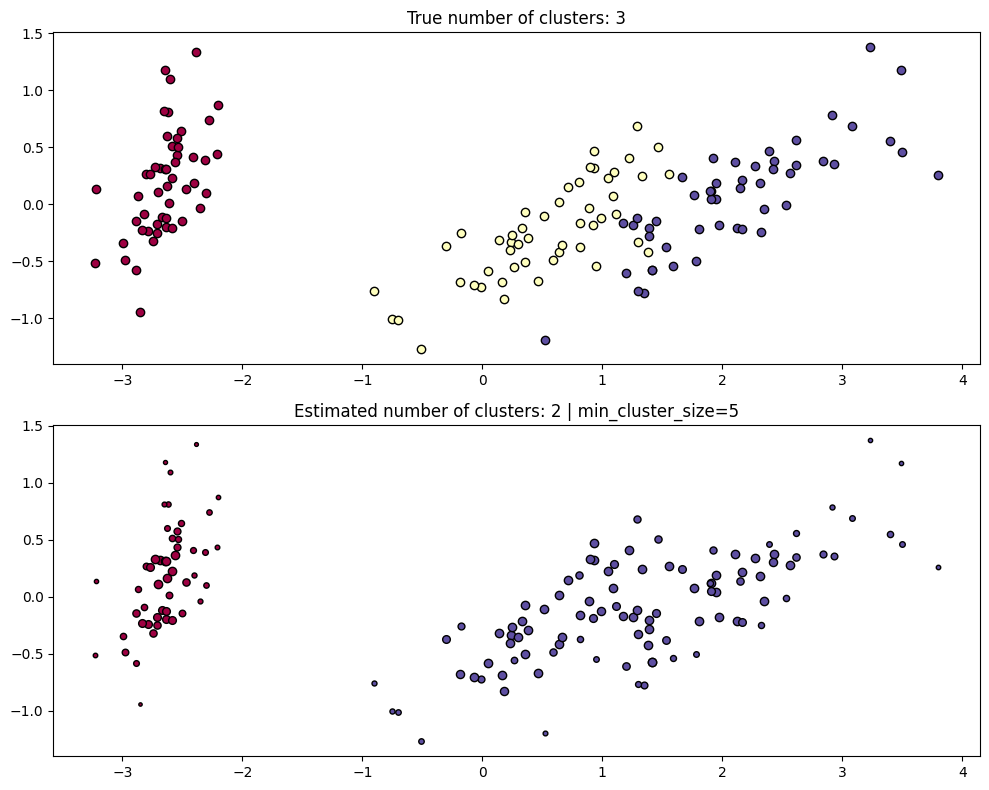

In [ ]:
X_pca = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
plot(X_pca, y_true, ground_truth=True, ax=axes[0])
plot(X_pca, labels, hdb.probabilities_, parameters={"min_cluster_size": 5}, ax=axes[1])

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

print(pd.crosstab(y_true, labels, rownames=['True label'], colnames=['HDBSCAN cluster']))
print(f"Adjusted Rand Index: {adjusted_rand_score(y_true, labels):.3f}")
print(f"Normalized Mutual Info: {normalized_mutual_info_score(y_true, labels):.3f}")

HDBSCAN cluster   0   1
True label             
0                50   0
1                 0  50
2                 0  50
Adjusted Rand Index: 0.568
Normalized Mutual Info: 0.734


HDBSCAN formed 2 clusters with 0 noise points on the iris dataset, while the original labels contain 3 species. The result therefore does not fully match the original labels (ARI = 0.568, NMI = 0.734). Setosa is recovered perfectly as its own cluster because it is well separated from the other species. Versicolor and virginica overlap in feature space with no low-density region between them, so HDBSCAN, which defines clusters by density, merges them into a single cluster. The result was identical for min_cluster_size values of 3, 5 and 10, which shows the 2-cluster structure comes from the data, not from the parameter choice. This illustrates that density-based clustering recovers natural groupings in the data, which do not always coincide with human-defined class labels.